# Task 1 — Model analysis

วิเคราะห์ผลโมเดลสุดท้ายจาก `Task1/train.py` (ต้องรัน `python Task1/train.py` ก่อน)
- out-of-fold (OOF) probabilities: `models/Task1/oof.npz`
- ผล CV: `reports/experiments/task1_cv.json`
- feature importance: `reports/experiments/task1_feature_importance.csv`

Metric ของ Kaggle คือ **F2 Score (Macro)** = ค่าเฉลี่ยของ F2 คลาส 0 และ F2 คลาส 1

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import fbeta_score, confusion_matrix, roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models" / "Task1" / "oof.npz").exists())
FIG = ROOT / "reports" / "figures"
oof = np.load(ROOT / "models" / "Task1" / "oof.npz")
cv = json.loads((ROOT / "reports" / "experiments" / "task1_cv.json").read_text())
y, p = oof["y"], oof["ensemble"]
THR = cv["results"]["ensemble"]["threshold"]

C_LEGIT, C_CHEAT, C_MACRO = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.family": ["Segoe UI", "Tahoma", "DejaVu Sans"], "figure.dpi": 110,
})
pd.DataFrame(cv["results"]).T[["auc", "macro_f2", "threshold"]].astype(float).round(4)

,auc,macro_f2,threshold
lgbm,0.8916,0.7793,0.380
xgb,0.8904,0.7797,0.415
ensemble,0.8916,0.7799,0.405


## 1. การเลือก threshold

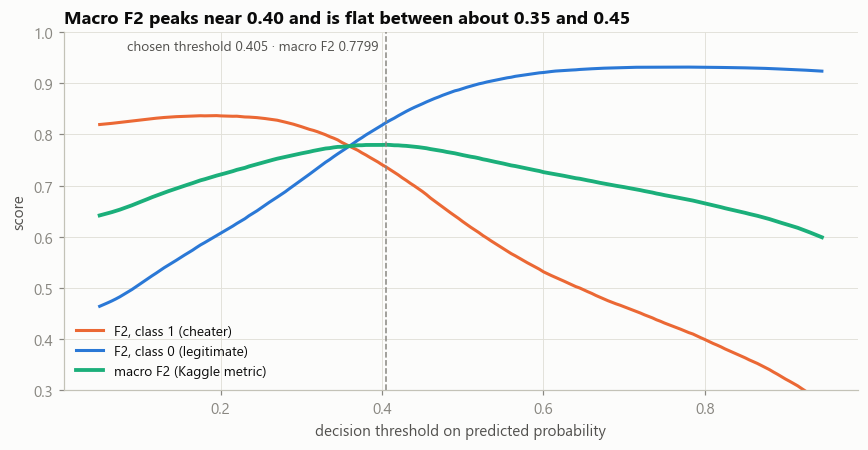

thresholds within 0.002 of the best macro F2: 0.365 - 0.425


In [2]:
grid = np.arange(0.05, 0.95, 0.005)
f2_0 = np.array([fbeta_score(y, (p >= t).astype(int), beta=2, pos_label=0) for t in grid])
f2_1 = np.array([fbeta_score(y, (p >= t).astype(int), beta=2, pos_label=1) for t in grid])
macro = (f2_0 + f2_1) / 2

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(grid, f2_1, color=C_CHEAT, lw=2, label="F2, class 1 (cheater)")
ax.plot(grid, f2_0, color=C_LEGIT, lw=2, label="F2, class 0 (legitimate)")
ax.plot(grid, macro, color=C_MACRO, lw=2.5, label="macro F2 (Kaggle metric)")
ax.axvline(THR, color=MUTED, lw=1, ls="--")
ax.text(THR - 0.01, 0.985, f"chosen threshold {THR:.3f} · macro F2 {macro[np.argmin(abs(grid - THR))]:.4f}",
        ha="right", va="top", color=INK2, fontsize=9)
ax.set_xlabel("decision threshold on predicted probability"); ax.set_ylabel("score")
ax.set_ylim(0.3, 1.0); ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.set_title("Macro F2 peaks near 0.40 and is flat between about 0.35 and 0.45")
fig.tight_layout(); fig.savefig(FIG / "task1_threshold_curve.png", bbox_inches="tight"); plt.show()

near = grid[macro >= macro.max() - 0.002]
print(f"thresholds within 0.002 of the best macro F2: {near.min():.3f} - {near.max():.3f}")

**สรุป:** ถ้าวัดแค่ F2 ของคลาส 1 threshold ที่ดีที่สุดจะต่ำมาก (ทายว่าโกงเกือบทุกคน)
แต่ Kaggle ใช้แบบ Macro ซึ่งรวม F2 ของคลาส 0 ด้วย threshold ที่ดีที่สุดจึงอยู่ราว 0.40
กราฟค่อนข้างแบนรอบจุดสูงสุด จึงไม่ไวต่อการเลือก threshold มากนัก

## 2. Confusion matrix ที่ threshold ที่เลือก

In [3]:
pred = (p >= THR).astype(int)
cm = confusion_matrix(y, pred)
display(pd.DataFrame(cm, index=["actual legit (0)", "actual cheater (1)"],
                     columns=["pred legit (0)", "pred cheater (1)"]))
print(f"precision(cheater) {cm[1,1] / cm[:,1].sum():.3f} | recall(cheater) {cm[1,1] / cm[1].sum():.3f} | "
      f"flagged share {pred.mean():.3f}")
print("per-fold macro F2:", np.round(cv["results"]["ensemble"]["fold_macro_f2"], 4).tolist())

,pred legit (0),pred cheater (1)
actual legit (0),48159,10932
actual cheater (1),7922,23803


precision(cheater) 0.685 | recall(cheater) 0.750 | flagged share 0.382
per-fold macro F2: [0.7796, 0.7795, 0.7823, 0.7744, 0.7834]


## 3. Distribution ของ probability แยกตามคลาสจริง

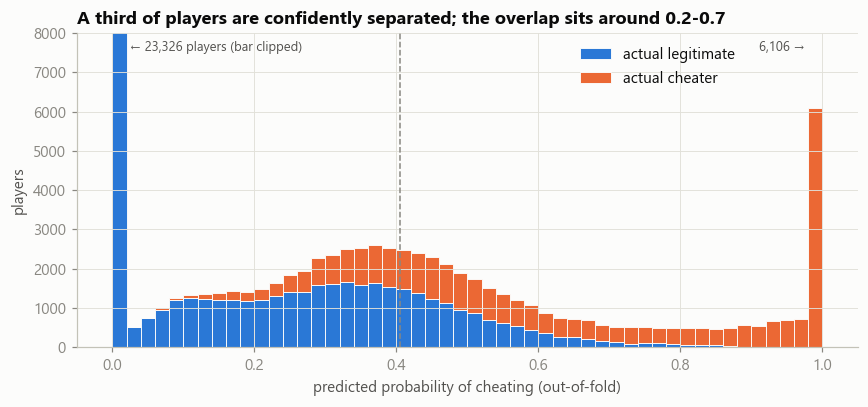

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(0, 1, 51)
ax.hist([p[y == 0], p[y == 1]], bins=bins, stacked=True, color=[C_LEGIT, C_CHEAT],
        label=["actual legitimate", "actual cheater"], edgecolor="#fcfcfb", linewidth=0.6)
ax.set_ylim(0, 8000)
ax.text(0.025, 7800, f"\u2190 {(p < 0.02).sum():,} players (bar clipped)", ha="left", va="top", fontsize=8.5, color=INK2)
ax.text(0.975, 7800, f"{(p >= 0.98).sum():,} \u2192", ha="right", va="top", fontsize=8.5, color=INK2)
ax.axvline(THR, color=MUTED, lw=1, ls="--")
ax.set_xlabel("predicted probability of cheating (out-of-fold)"); ax.set_ylabel("players")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(0.86, 1.0))
ax.set_title("A third of players are confidently separated; the overlap sits around 0.2-0.7")
fig.tight_layout(); fig.savefig(FIG / "task1_oof_proba.png", bbox_inches="tight"); plt.show()

## 4. Feature importance (LightGBM gain)

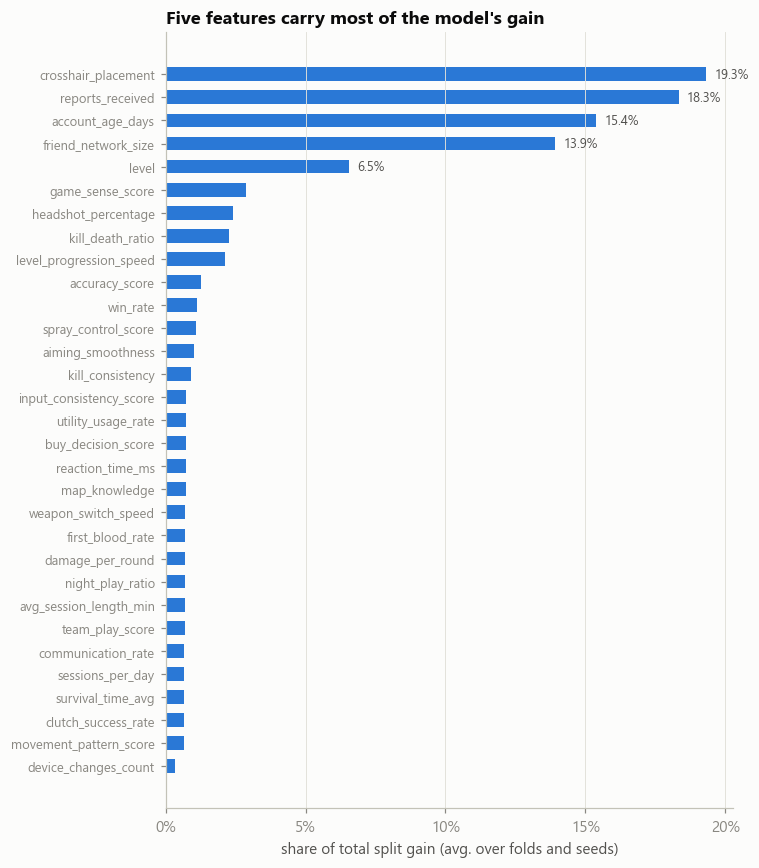

In [5]:
imp = pd.read_csv(ROOT / "reports" / "experiments" / "task1_feature_importance.csv", index_col=0)["lgbm_gain"]
share = (imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(share.index, share.values, color=C_LEGIT, height=0.6)
for i, v in enumerate(share.values):
    if i >= len(share) - 5:
        ax.text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=8.5, color=INK2)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Five features carry most of the model's gain")
ax.set_xlabel("share of total split gain (avg. over folds and seeds)")
fig.tight_layout(); fig.savefig(FIG / "task1_feature_importance.png", bbox_inches="tight"); plt.show()

**สรุป:** feature ที่สำคัญที่สุด 5 อันดับแรกคือ `crosshair_placement`, `reports_received`,
`account_age_days`, `friend_network_size`, `level` ทั้งหมดเป็น feature ที่มี
**ช่วงค่าที่พบเฉพาะคลาสเดียว** (ดู EDA) เช่น บัญชีอายุเกิน 1,000 วันหรือมีเพื่อนเกิน 269 คนเป็นผู้เล่นปกติทั้งหมด
`account_age_days` และ `friend_network_size` แยกคลาสได้ไม่ดีเมื่อดูเดี่ยวๆ (AUC ~0.54 และ ~0.53)
แต่โมเดลใช้ประโยชน์จากขอบเขตเหล่านี้ได้มาก

**ความหมายทางธุรกิจ:** ในกลุ่มบัญชีที่ถูกรายงาน คนโกงไม่ได้มีสถิติการยิงสูงกว่าผู้เล่นปกติ
(K/D, headshot และ accuracy ของคนโกงต่ำกว่าเล็กน้อย) ตรงกับโจทย์ที่บอกว่าบัญชีที่ถูกรายงานจำนวนมาก
เป็นผู้เล่นเก่งที่ไม่ได้โกง สัญญาณที่ใช้ได้จริงจึงมาจากประวัติบัญชี (อายุบัญชี, เพื่อน, เลเวล)
และพฤติกรรมการเล็ง (`crosshair_placement`) มากกว่าสถิติผลงาน